In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.shape

(1460, 81)

1460= number of houses(rows)
81= num of cols giving characteristics of the houses

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [6]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values.sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [7]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

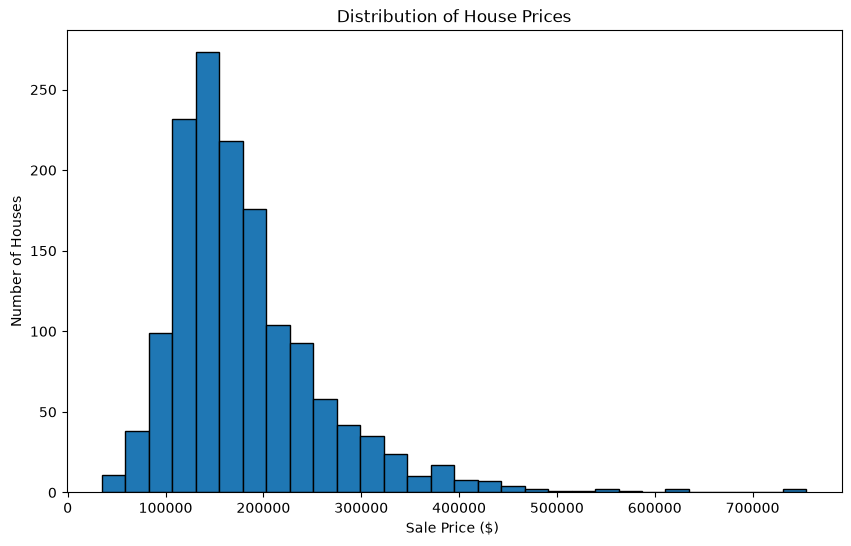

In [8]:
plt.figure(figsize=(10,6))

plt.hist(df["SalePrice"], bins=30, edgecolor="black")

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price ($) ")
plt.ylabel("Number of Houses")

plt.show()

What price range has the most houses? Approximately $125,000–$175,000, with the tallest bar around $130,000–$155,000

Are most houses relatively inexpensive? yes most of them are conecntrated below 250k

Are there unusually expensive houses? yes a few of them lie in the range of 500k to 750k

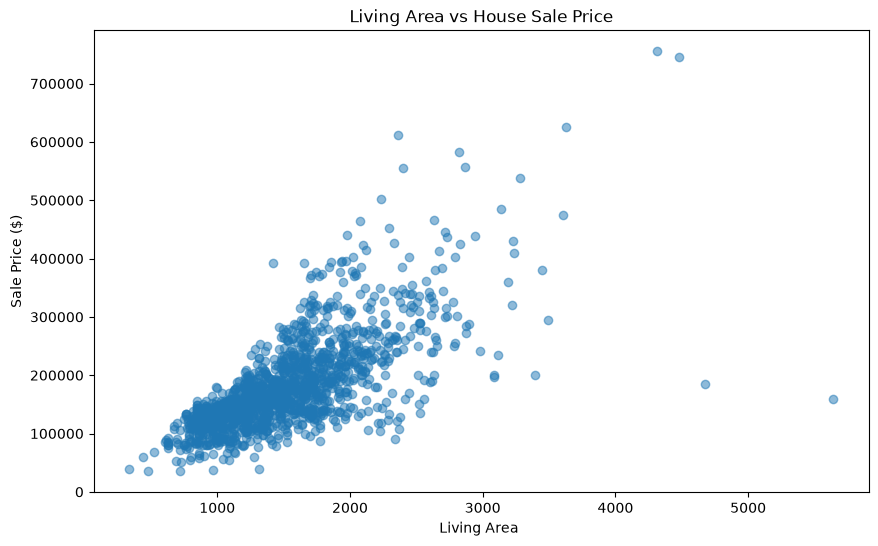

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5)

plt.title("Living Area vs House Sale Price")
plt.xlabel("Living Area ")
plt.ylabel("Sale Price ($)")

plt.show()

Do houses with more living space generally sell for higher prices?
Most of the dots are folling an upward trend. As the living area increases, the selling prices are also increasing

Are there any unusually large houses with surprisingly low selling prices?  yes they areone or two that are actual outliers in our data that are being sold at a low price. 


In [10]:
correlation = df["GrLivArea"].corr(df["SalePrice"])

print("Correlation:", correlation)

Correlation: 0.7086244776126521


The correlation between the lving area and the sale price is at 0.709 this produces a strong positive realtionship. This means that the larger houses are being sold for higher prices, although there could be other factors that we must take into account that might be influencing the sale price.

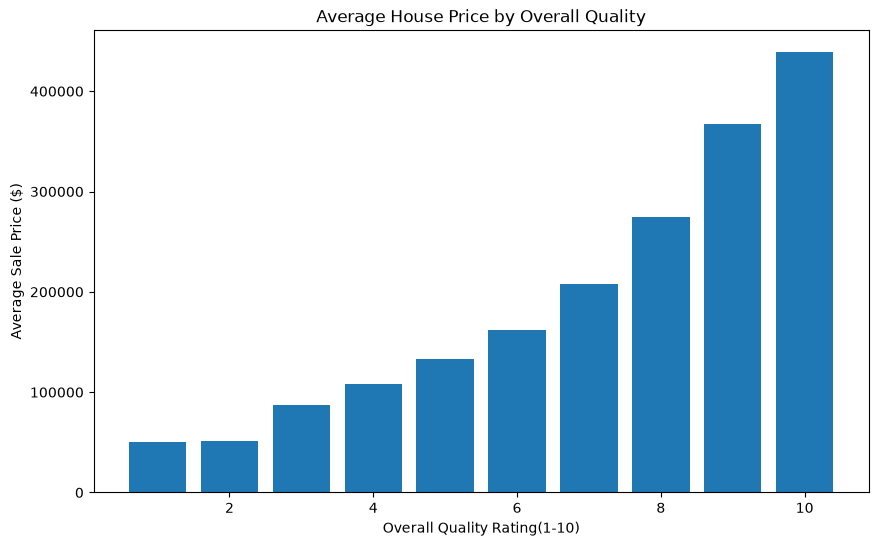

In [11]:
quality_prices = df.groupby("OverallQual")["SalePrice"].mean()

plt.figure(figsize=(10, 6))

plt.bar(quality_prices.index, quality_prices.values)

plt.title("Average House Price by Overall Quality")
plt.xlabel("Overall Quality Rating(1-10)")
plt.ylabel("Average Sale Price ($)")

plt.show()

The graph that we have illustrates that houses with higher quality rating will sell for more of a higher price. There is also a significant increase in the avg selling prices between the 8 and 10 ratings. This suggest that the overall quality is an important feature to include when predicting the house prices

In [14]:
quality_correlation = df["OverallQual"].corr(df["SalePrice"])

print("Overall Quality Correlation:", quality_correlation)

Overall Quality Correlation: 0.7909816005838051


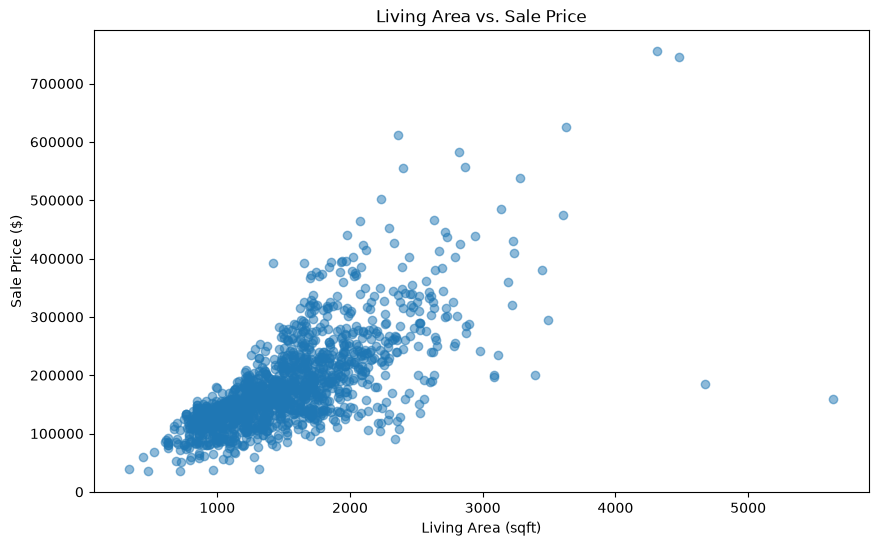

In [19]:
plt.figure(figsize=(10,6))

plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5)

plt.title("Living Area vs. Sale Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Sale Price ($)")

plt.show()